# **Preparing Dependancies**

In [22]:
!pip install -q diffusers transformers accelerate safetensors torch torchvision pillow matplotlib scipy

In [23]:
import gc
import torch
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw, ImageFilter
from transformers import pipeline as hf_pipeline
from diffusers import (
    StableDiffusionPipeline,
    StableDiffusionInpaintPipeline,
    StableDiffusionImg2ImgPipeline,
    EulerAncestralDiscreteScheduler,
    DPMSolverMultistepScheduler,
    DDIMScheduler,
)

device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Device: {device}")

Device: cuda


# **Kriteria 1: Melakukan Image Generation dari Teks (Text-to-Image)**

## **Load Base Pipeline Model**

In [24]:
MODEL_ID = "stable-diffusion-v1-5/stable-diffusion-v1-5"

pipe = StableDiffusionPipeline.from_pretrained(
    MODEL_ID,
    torch_dtype=torch.float16,
    safety_checker=None
).to(device)

default_scheduler_config = pipe.scheduler.config

PROMPT_ASTRONAUT = (
    "an astronaut with full white spacesuit, standing on a flat moon plain, "
    "with earth in the background, minimal detail, 2D digital illustration"
)

NEGATIVE_PROMPT = (
    "photorealistic, realistic, photograph, 3d render, messy, blurry, low quality, "
    "bad art, ugly, sketch, grainy, unfinished, chromatic aberration"
)

SEED = 222

Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

You have disabled the safety checker for <class 'diffusers.pipelines.stable_diffusion.pipeline_stable_diffusion.StableDiffusionPipeline'> by passing `safety_checker=None`. Ensure that you abide to the conditions of the Stable Diffusion license and do not expose unfiltered results in services or applications open to the public. Both the diffusers team and Hugging Face strongly recommend to keep the safety filter enabled in all public facing circumstances, disabling it only for use-cases that involve analyzing network behavior or auditing its results. For more information, please have a look at https://github.com/huggingface/diffusers/pull/254 .


## **Generate Image (generate_simple_image)**
Pada bagian ini, Anda akan menghasilkan gambar dari teks. Sasarannya adalah menghasilkan gambar yang mendekati gambar contoh di bawah ini, yaitu seorang astronaut di permukaan bulan dengan gaya digital art 2D. Perhatikan empat elemen visual utama berikut:

*   Astronaut berbaju putih
*   Permukaan bulan
*   Bumi di langit
*   Gaya ilustrasi 2D

(bukan foto realistis).

Gunakan Seed bernilai 222 dan negative prompt yang telah ditetapkan. Pastikan prompt yang Anda gunakan sama pada kedua fungsi agar hasilnya dapat dibandingkan secara objektif.

### **Referensi output:**

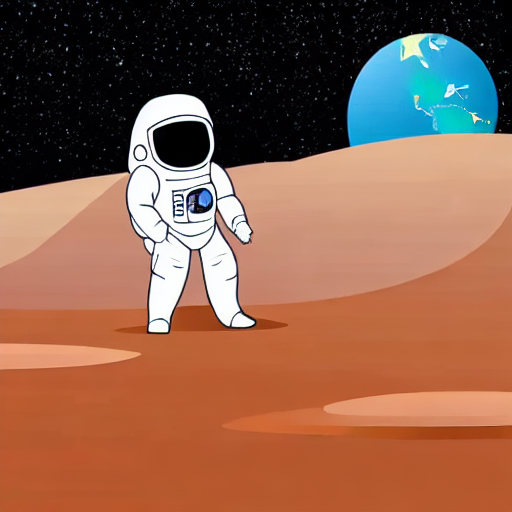

  0%|          | 0/25 [00:00<?, ?it/s]

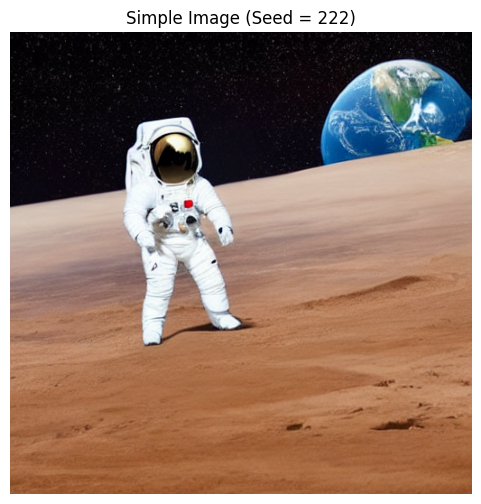

In [25]:
def generate_simple_image(prompt, negative_prompt, seed):
    pipe.scheduler = DDIMScheduler.from_config(default_scheduler_config)
    generator = torch.Generator(device=device).manual_seed(seed)
    result = pipe(
        prompt=prompt,
        negative_prompt=negative_prompt,
        guidance_scale=7.5,
        num_inference_steps=25,
        generator=generator
    )
    return result.images[0]

simple_img = generate_simple_image(PROMPT_ASTRONAUT, NEGATIVE_PROMPT, SEED)

plt.figure(figsize=(6, 6))
plt.imshow(simple_img)
plt.title("Simple Image (Seed = 222)")
plt.axis("off")
plt.show()

## **Generate Image with Hyperparameter Configuration (generate_advanced_image)**
Tetap gunakan Seed bernilai 222 dan negative prompt yang telah ditetapkan. Pastikan prompt yang Anda gunakan sama pada kedua fungsi agar hasilnya dapat dibandingkan secara objektif.

### **Referensi Output:**

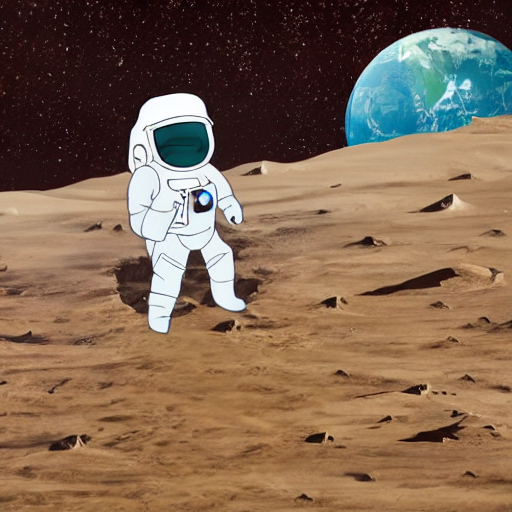

  0%|          | 0/80 [00:00<?, ?it/s]

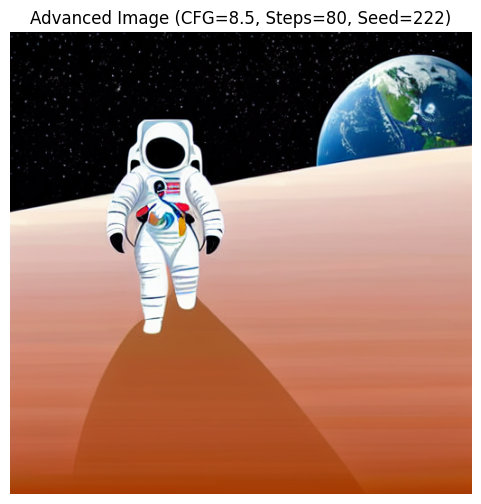

In [26]:
def generate_advanced_image(prompt, negative_prompt, seed, guidance_scale=8.5, num_inference_step=80):
    pipe.scheduler = DPMSolverMultistepScheduler.from_config(default_scheduler_config)
    generator = torch.Generator(device=device).manual_seed(seed)
    result = pipe(
        prompt=prompt,
        negative_prompt=negative_prompt,
        guidance_scale=guidance_scale,
        num_inference_steps=num_inference_step,
        generator=generator
    )
    return result.images[0]

advanced_img = generate_advanced_image(
    prompt=PROMPT_ASTRONAUT,
    negative_prompt=NEGATIVE_PROMPT,
    seed=SEED,
    guidance_scale=8.5,
    num_inference_step=80
)

plt.figure(figsize=(6, 6))
plt.imshow(advanced_img)
plt.title("Advanced Image (CFG=8.5, Steps=80, Seed=222)")
plt.axis("off")
plt.show()

## **Guidance Scale Comparison**

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

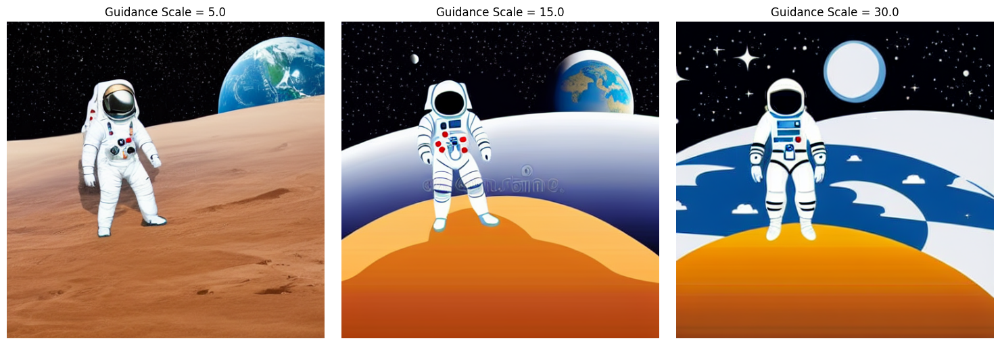

In [27]:
guidance_values = [5.0, 15.0, 30.0]
guidance_images = []

for cfg in guidance_values:
    img = generate_advanced_image(
        prompt=PROMPT_ASTRONAUT,
        negative_prompt=NEGATIVE_PROMPT,
        seed=SEED,
        guidance_scale=cfg,
        num_inference_step=30
    )
    guidance_images.append(img)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, img, cfg in zip(axes, guidance_images, guidance_values):
    ax.imshow(img)
    ax.set_title(f"Guidance Scale = {cfg}")
    ax.axis("off")
plt.tight_layout()
plt.show()

## Guidance Scale Explanation:
- *Gambar dengan "Scale" Rendah:* Pada nilai *guidance scale* rendah (**5.0**), model memiliki kebebasan interpretasi yang lebih luas sehingga pencahayaan dan gradasi warna tampak lebih lembut. Namun, kepatuhan terhadap detail spesifik *prompt* menjadi lebih longgar sehingga beberapa elemen latar ilustrasi 2D terlihat lebih sederhana.
- *Gambar dengan "Scale" Tinggi:* Pada nilai *guidance scale* tinggi (**15.0** hingga **30.0**), gambar mengikuti seluruh kata kunci dalam *prompt* secara jauh lebih ketat. Kontras garis, saturasi warna, serta ketajaman bentuk astronaut dan permukaan bulan meningkat drastis, meskipun pada nilai ekstrem (**30.0**) mulai muncul saturasi warna yang terlalu pekat.

## **Inference Steps Comparison**

  0%|          | 0/10 [00:00<?, ?it/s]

  0%|          | 0/40 [00:00<?, ?it/s]

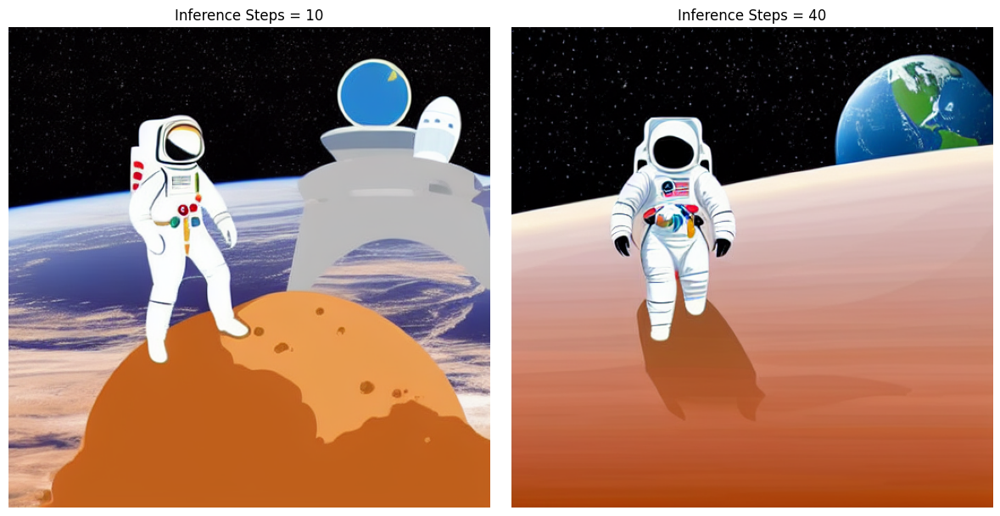

In [28]:
step_values = [10, 40]
step_images = []

for steps in step_values:
    img = generate_advanced_image(
        prompt=PROMPT_ASTRONAUT,
        negative_prompt=NEGATIVE_PROMPT,
        seed=SEED,
        guidance_scale=8.5,
        num_inference_step=steps
    )
    step_images.append(img)

fig, axes = plt.subplots(1, 2, figsize=(12, 6))
for ax, img, steps in zip(axes, step_images, step_values):
    ax.imshow(img)
    ax.set_title(f"Inference Steps = {steps}")
    ax.axis("off")
plt.tight_layout()
plt.show()

## Inference Step Explanation:
- *Gambar dengan "Step" Rendah:* Pada jumlah langkah rendah (**10 steps**), proses *denoising* berhenti terlalu cepat sehingga kontur helm astronaut, kawah bulan, dan bentuk Bumi terlihat kurang tajam serta masih menyisakan bagian yang belum sepenuhnya halus.
- *Gambar dengan "Step" Tinggi:* Pada jumlah langkah tinggi (**40 steps**), proses pengurangan *noise* berjalan jauh lebih matang dan stabil. Garis ilustrasi 2D menjadi jauh lebih rapi, tekstur permukaan bulan terlihat bersih, dan komposisi keseluruhan tampak jauh lebih solid tanpa artefak.

## **Batch Inference from One Prompt**

  0%|          | 0/30 [00:00<?, ?it/s]

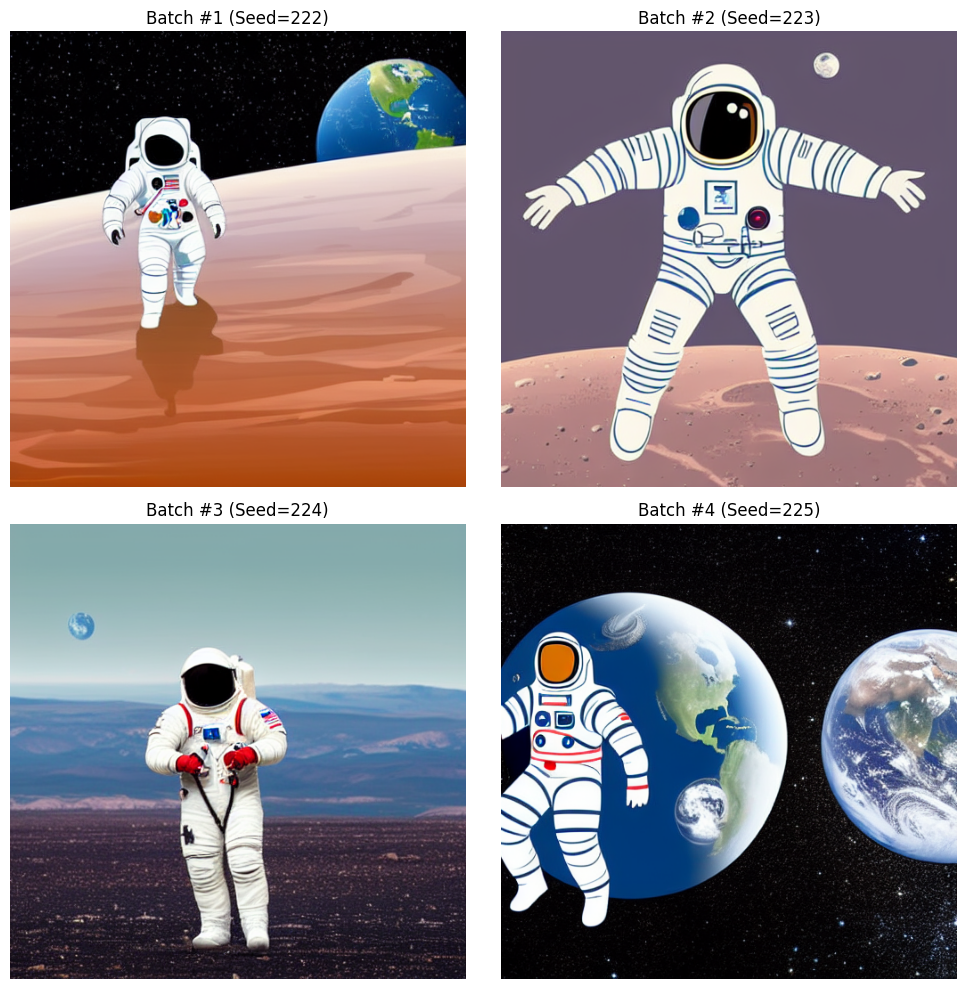

In [29]:
pipe.scheduler = DPMSolverMultistepScheduler.from_config(default_scheduler_config)
batch_generators = [torch.Generator(device=device).manual_seed(SEED + i) for i in range(4)]

batch_images = pipe(
    prompt=[PROMPT_ASTRONAUT] * 4,
    negative_prompt=[NEGATIVE_PROMPT] * 4,
    guidance_scale=8.5,
    num_inference_steps=30,
    generator=batch_generators
).images

fig, axes = plt.subplots(2, 2, figsize=(10, 10))
for idx, (ax, img) in enumerate(zip(axes.flat, batch_images)):
    ax.imshow(img)
    ax.set_title(f"Batch #{idx + 1} (Seed={SEED + idx})")
    ax.axis("off")
plt.tight_layout()
plt.show()

## **Load Scheduler**

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

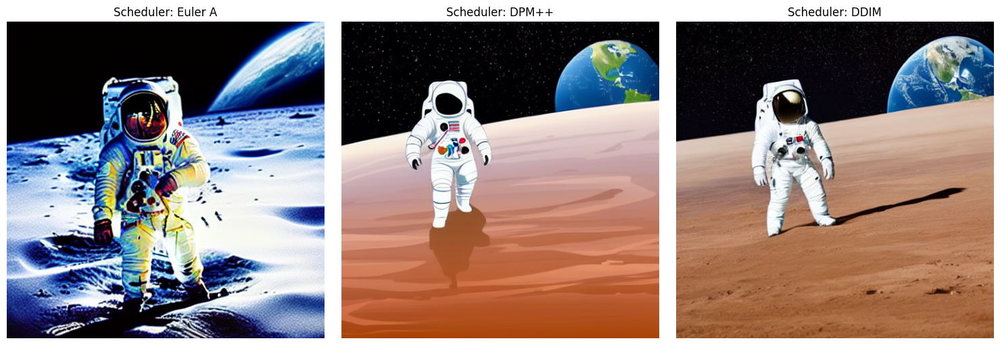

In [30]:
def load_scheduler(pipe, scheduler_name):
    if scheduler_name == "Euler A":
        pipe.scheduler = EulerAncestralDiscreteScheduler.from_config(pipe.scheduler.config)
    elif scheduler_name == "DPM++":
        pipe.scheduler = DPMSolverMultistepScheduler.from_config(pipe.scheduler.config)
    elif scheduler_name == "DDIM":
        pipe.scheduler = DDIMScheduler.from_config(pipe.scheduler.config)
    else:
        raise ValueError(f"Scheduler tidak dikenal: {scheduler_name}")
    return pipe

scheduler_names = ["Euler A", "DPM++", "DDIM"]
scheduler_images = []

for name in scheduler_names:
    pipe = load_scheduler(pipe, name)
    generator = torch.Generator(device=device).manual_seed(SEED)
    img = pipe(
        prompt=PROMPT_ASTRONAUT,
        negative_prompt=NEGATIVE_PROMPT,
        guidance_scale=8.5,
        num_inference_steps=30,
        generator=generator
    ).images[0]
    scheduler_images.append(img)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, img, name in zip(axes, scheduler_images, scheduler_names):
    ax.imshow(img)
    ax.set_title(f"Scheduler: {name}")
    ax.axis("off")
plt.tight_layout()
plt.show()

## Scheduler Comparation:
- *Gambar dengan "Euler A Scheduler":* Menghasilkan tampilan ilustrasi yang lebih artistik dan dinamis dengan transisi warna yang lembut, karena sifat *ancestral*-nya menambahkan variasi acak pada setiap langkah *sampling*.
- *Gambar dengan "DPM++ Scheduler":* Menghasilkan detail yang sangat tajam, kontras warna yang solid, serta garis objek yang presisi dan cepat konvergen pada jumlah *inference steps* menengah.
- *Gambar dengan "DDIM Scheduler":* Menghasilkan komposisi yang lebih deterministik dan stabil dengan gradasi warna yang halus serta struktur latar yang lebih tenang dibandingkan *Euler A*.

# **Kriteria 2: Menyempurnakan Gambar Melalui Image-to-Image**

## **Inpainting**

**Perhatian:** Gunakan gambar hasil `generate_advanced_image()` atau `generate_simple_image()` sebagai `image`, bukan gambar baru.

Hasil Inpainting yang Anda lakukan perlu dibuat semirip mungkin atau setidaknya menambahkan broken satelite seperti pada Gambar yang ditetapkan berikut ini. (Gunakan Seed bernilai 9)

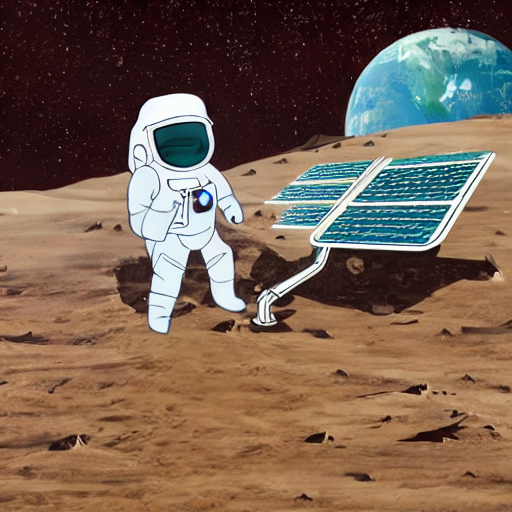

### **Load Model Inpainting**

In [31]:
INPAINT_MODEL_ID = "stable-diffusion-v1-5/stable-diffusion-inpainting"

pipe_inpaint = StableDiffusionInpaintPipeline.from_pretrained(
    INPAINT_MODEL_ID,
    torch_dtype=torch.float16,
    safety_checker=None
).to(device)

print("Inpainting pipeline berhasil dimuat!")

Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

An error occurred while trying to fetch /root/.cache/huggingface/hub/models--stable-diffusion-v1-5--stable-diffusion-inpainting/snapshots/8a4288a76071f7280aedbdb3253bdb9e9d5d84bb/vae: Error no file named diffusion_pytorch_model.safetensors found in directory /root/.cache/huggingface/hub/models--stable-diffusion-v1-5--stable-diffusion-inpainting/snapshots/8a4288a76071f7280aedbdb3253bdb9e9d5d84bb/vae.
Defaulting to unsafe serialization. Pass `allow_pickle=False` to raise an error instead.
An error occurred while trying to fetch /root/.cache/huggingface/hub/models--stable-diffusion-v1-5--stable-diffusion-inpainting/snapshots/8a4288a76071f7280aedbdb3253bdb9e9d5d84bb/unet: Error no file named diffusion_pytorch_model.safetensors found in directory /root/.cache/huggingface/hub/models--stable-diffusion-v1-5--stable-diffusion-inpainting/snapshots/8a4288a76071f7280aedbdb3253bdb9e9d5d84bb/unet.
Defaulting to unsafe serialization. Pass `allow_pickle=False` to raise an error instead.


Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

You have disabled the safety checker for <class 'diffusers.pipelines.stable_diffusion.pipeline_stable_diffusion_inpaint.StableDiffusionInpaintPipeline'> by passing `safety_checker=None`. Ensure that you abide to the conditions of the Stable Diffusion license and do not expose unfiltered results in services or applications open to the public. Both the diffusers team and Hugging Face strongly recommend to keep the safety filter enabled in all public facing circumstances, disabling it only for use-cases that involve analyzing network behavior or auditing its results. For more information, please have a look at https://github.com/huggingface/diffusers/pull/254 .


Inpainting pipeline berhasil dimuat!


### **Manual Masking**

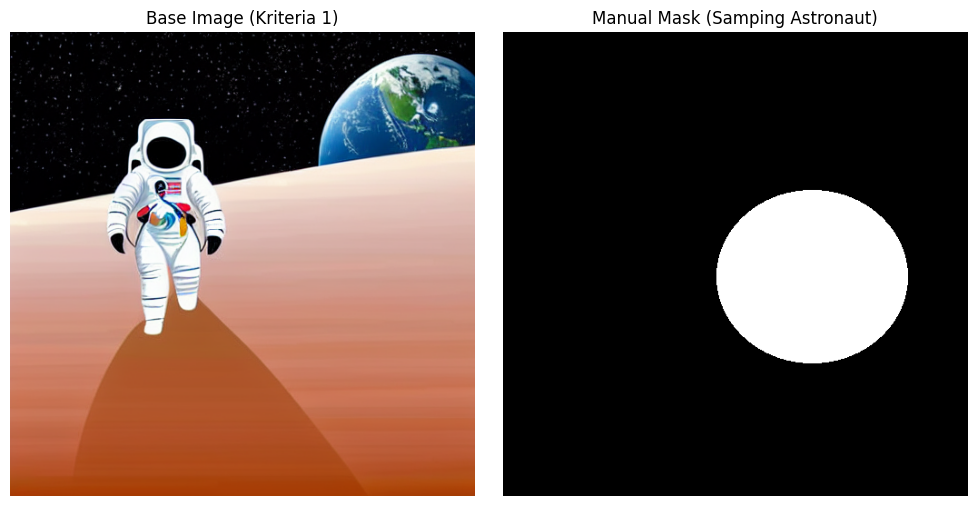

In [32]:
base_for_inpaint = advanced_img.copy().resize((512, 512))
manual_mask = Image.new("L", (512, 512), 0)
draw = ImageDraw.Draw(manual_mask)

# Area mask di samping kanan astronaut & di bawah planet Bumi
draw.ellipse([235, 175, 445, 365], fill=255)

fig, axes = plt.subplots(1, 2, figsize=(10, 5))
axes[0].imshow(base_for_inpaint)
axes[0].set_title("Base Image (Kriteria 1)")
axes[1].imshow(manual_mask, cmap="gray")
axes[1].set_title("Manual Mask (Samping Astronaut)")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

### **Generate**

  0%|          | 0/50 [00:00<?, ?it/s]

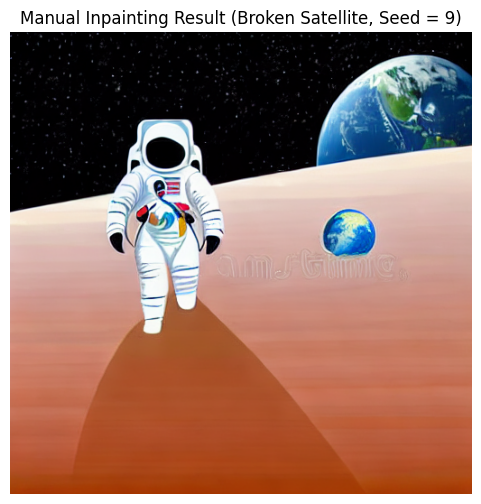

In [33]:
def inpaint_engine(image, mask, prompt, negative_prompt=NEGATIVE_PROMPT, seed=9, strength=1.0, guidance_scale=12.0, num_inference_steps=50):
    if image.mode != "RGB":
        image = image.convert("RGB")
    if mask.mode != "L":
        mask = mask.convert("L")
    if image.size != mask.size:
        mask = mask.resize(image.size, resample=Image.NEAREST)

    generator = torch.Generator(device=device).manual_seed(seed)
    output = pipe_inpaint(
        prompt=prompt,
        negative_prompt=negative_prompt,
        image=image,
        mask_image=mask,
        strength=strength,
        guidance_scale=guidance_scale,
        num_inference_steps=num_inference_steps,
        generator=generator
    )
    return output.images[0]

PROMPT_SATELLITE = (
    "a broken satellite with blue solar panels standing on the moon surface, "
    "2D digital illustration, crisp lines, vibrant colors"
)

manual_inpaint_img = inpaint_engine(
    image=base_for_inpaint,
    mask=manual_mask,
    prompt=PROMPT_SATELLITE,
    seed=9,
    strength=1.0,
    guidance_scale=12.0,
    num_inference_steps=50
)

plt.figure(figsize=(6, 6))
plt.imshow(manual_inpaint_img)
plt.title("Manual Inpainting Result (Broken Satellite, Seed = 9)")
plt.axis("off")
plt.show()

## **Inpainting Menggunakan Automasking**

Anda bebas untuk melakukan inpainting di area manapun menggunakan model segmentation. Terapkan inpainting pada gambar hasil inpainting manual di level basic sebelumnya.

### **load Model Segmentation Untuk Masking**

In [34]:
seg_pipe = hf_pipeline(
    "image-segmentation",
    model="nvidia/segformer-b0-finetuned-ade-512-512",
    device=0 if device == "cuda" else -1
)

print("Model segmentasi berhasil dimuat!")

Loading weights:   0%|          | 0/208 [00:00<?, ?it/s]

Model segmentasi berhasil dimuat!


### **Masking with Segmentation Model**

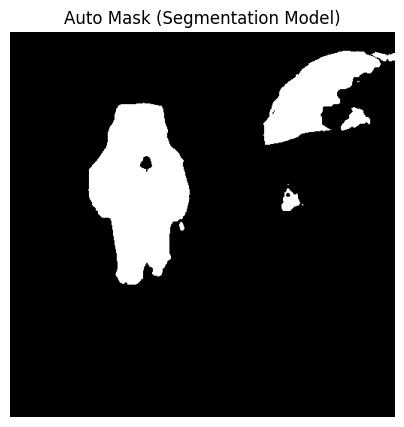

In [35]:
segments = seg_pipe(manual_inpaint_img)
auto_mask = Image.new("L", manual_inpaint_img.size, 0)

for seg in segments:
    if seg["label"] in ["person", "sky"]:
        mask_arr = np.array(seg["mask"])
        auto_mask = Image.fromarray(np.maximum(np.array(auto_mask), mask_arr))
        if seg["label"] == "person":
            break

del seg_pipe
gc.collect()
if device == "cuda":
    torch.cuda.empty_cache()

plt.figure(figsize=(5, 5))
plt.imshow(auto_mask, cmap="gray")
plt.title("Auto Mask (Segmentation Model)")
plt.axis("off")
plt.show()

### **Generate**

  0%|          | 0/32 [00:00<?, ?it/s]

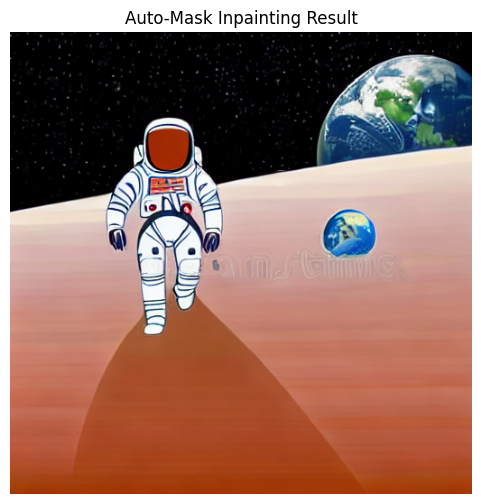

In [36]:
auto_inpaint_img = inpaint_engine(
    image=manual_inpaint_img,
    mask=auto_mask,
    prompt="2d digital art illustration of an astronaut wearing a bright orange and white spacesuit, clean vector art",
    seed=9,
    strength=0.80,
    guidance_scale=8.5,
    num_inference_steps=40
)

plt.figure(figsize=(6, 6))
plt.imshow(auto_inpaint_img)
plt.title("Auto-Mask Inpainting Result")
plt.axis("off")
plt.show()

## **Outpainting**

**Perhatian:** Gunakan gambar hasil inpainting (manual atau otomatis) sebagai input pada tahap ini.

Pastikan outpainting yang dilakukan mendekati gambar yang diharapkan di bawah ini dan terlihat natural dan masih berhubungan dengan gambar dasar.

###**Referensi Expected Output:**

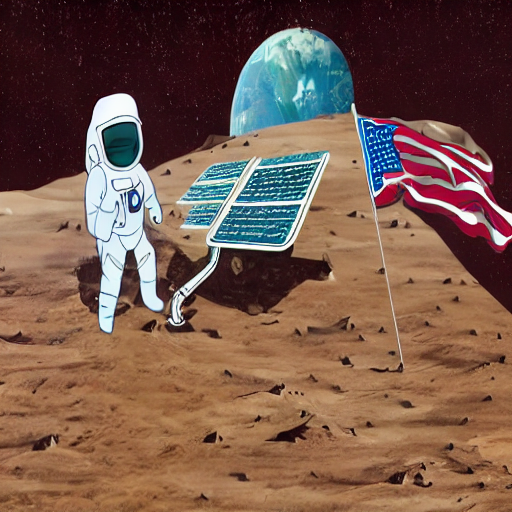

### **Prepare the Canvas**

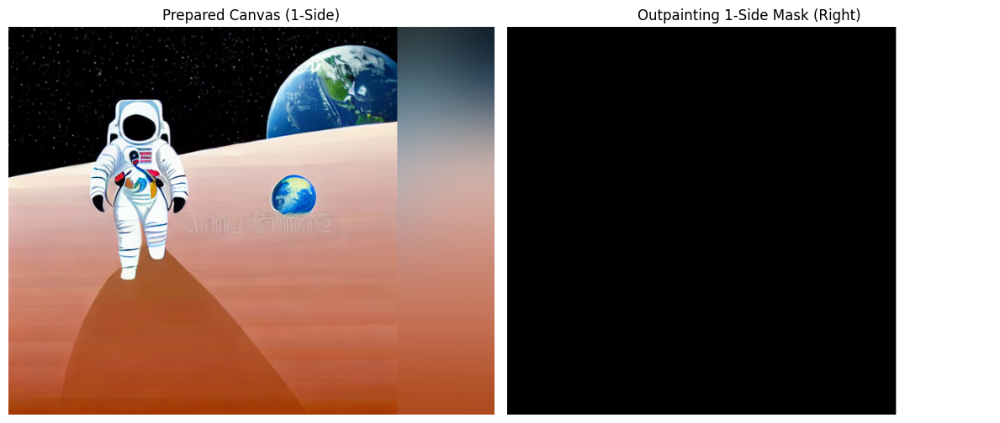

In [37]:
def prepare_outpainting(image, direction="right", expand_pixels=128):
    w, h = image.size
    if direction in ["left", "right"]:
        new_w, new_h = w + expand_pixels, h
    else:
        new_w, new_h = w, h + expand_pixels

    new_w -= new_w % 8
    new_h -= new_h % 8

    bg = image.resize((new_w, new_h), resample=Image.BICUBIC)
    bg = bg.filter(ImageFilter.GaussianBlur(radius=50))
    canvas = bg.copy()

    paste_x = 0 if direction == "right" else (new_w - w if direction == "left" else 0)
    paste_y = 0 if direction == "bottom" else (new_h - h if direction == "top" else 0)
    canvas.paste(image, (paste_x, paste_y))

    mask = Image.new("L", (new_w, new_h), 255)
    inner_box = Image.new("L", (w, h), 0)
    mask.paste(inner_box, (paste_x, paste_y))
    return canvas, mask

canvas_1side, mask_1side = prepare_outpainting(manual_inpaint_img, direction="right", expand_pixels=128)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].imshow(canvas_1side)
axes[0].set_title("Prepared Canvas (1-Side)")
axes[1].imshow(mask_1side, cmap="gray")
axes[1].set_title("Outpainting 1-Side Mask (Right)")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

### **Generate**

  0%|          | 0/38 [00:00<?, ?it/s]

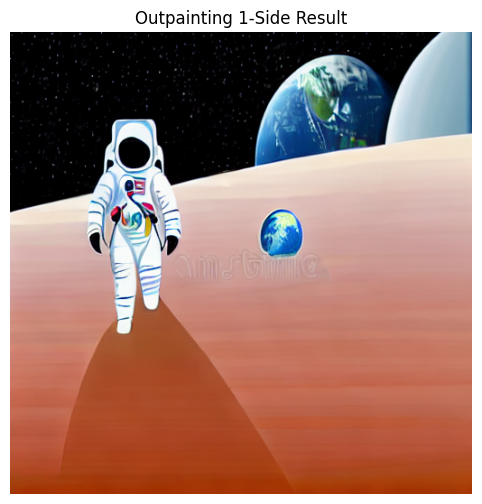

In [38]:
outpaint_1side_img = inpaint_engine(
    image=canvas_1side,
    mask=mask_1side,
    prompt=PROMPT_ASTRONAUT,
    seed=222,
    strength=0.95,
    guidance_scale=8.5,
    num_inference_steps=40
)

plt.figure(figsize=(8, 6))
plt.imshow(outpaint_1side_img)
plt.title("Outpainting 1-Side Result")
plt.axis("off")
plt.show()

## **Outpainting Zoom Out**

**Perhatian:** Gunakan gambar hasil outpainting sebelumnya sebagai input pada tahap ini.

Pada tahap ini Anda tidak diharuskan untuk meniru spesifik satu gambar saja, tetapi berikut beberapa output yang dapat dijadikan referensi.

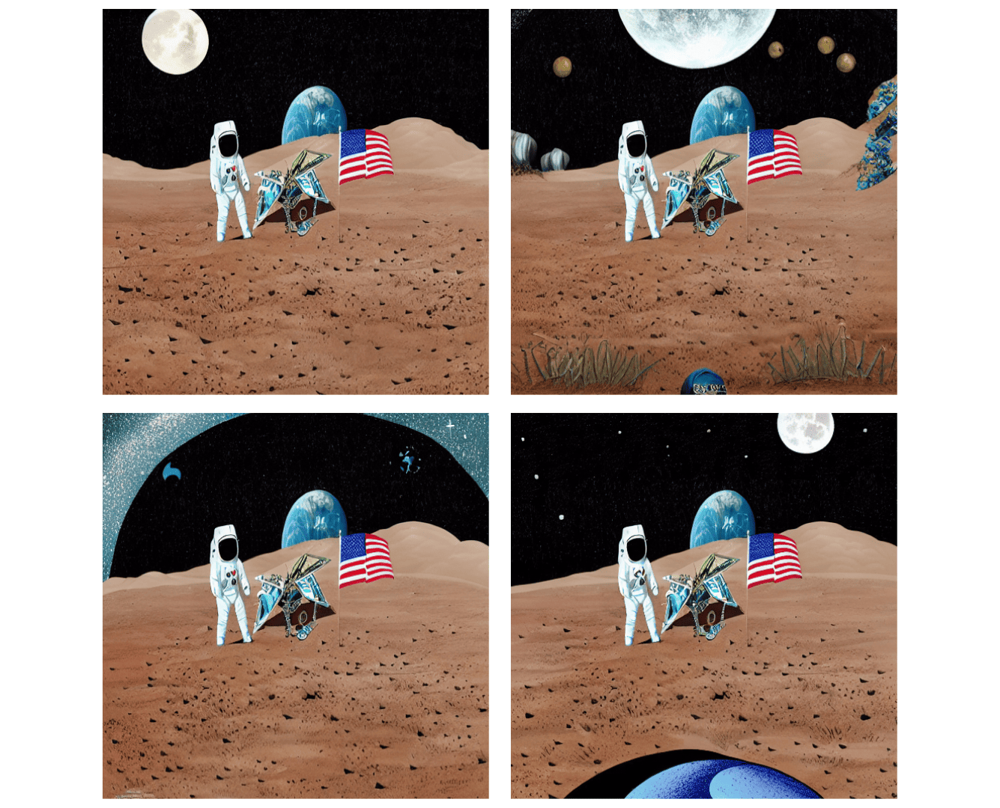

### **Prepare Canvas for Zoom Out**

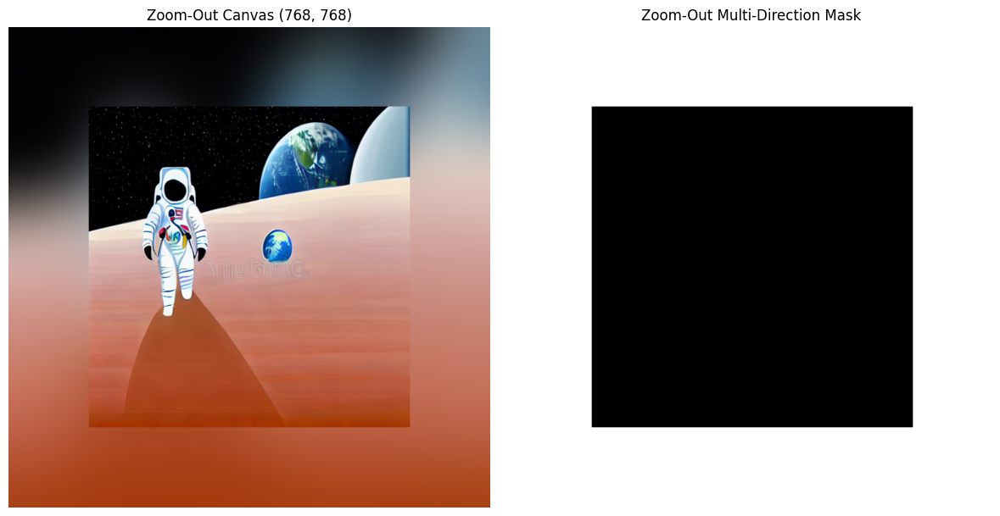

In [39]:
def prepare_zoom_out_canvas(image, expand_pixels=128):
    w, h = image.size
    new_w = w + (expand_pixels * 2)
    new_h = h + (expand_pixels * 2)

    new_w -= (new_w % 8)
    new_h -= (new_h % 8)

    bg = image.resize((new_w, new_h), resample=Image.BICUBIC)
    bg = bg.filter(ImageFilter.GaussianBlur(radius=50))
    canvas = bg.copy()

    paste_x = (new_w - w) // 2
    paste_y = (new_h - h) // 2
    canvas.paste(image, (paste_x, paste_y))

    mask = Image.new("L", (new_w, new_h), 255)
    inner_box = Image.new("L", (w, h), 0)
    mask.paste(inner_box, (paste_x, paste_y))

    return canvas, mask

zoom_canvas, zoom_mask = prepare_zoom_out_canvas(outpaint_1side_img, expand_pixels=128)

fig, axes = plt.subplots(1, 2, figsize=(12, 6))
axes[0].imshow(zoom_canvas)
axes[0].set_title(f"Zoom-Out Canvas {zoom_canvas.size}")
axes[1].imshow(zoom_mask, cmap="gray")
axes[1].set_title("Zoom-Out Multi-Direction Mask")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

### **Generate**

  0%|          | 0/38 [00:00<?, ?it/s]

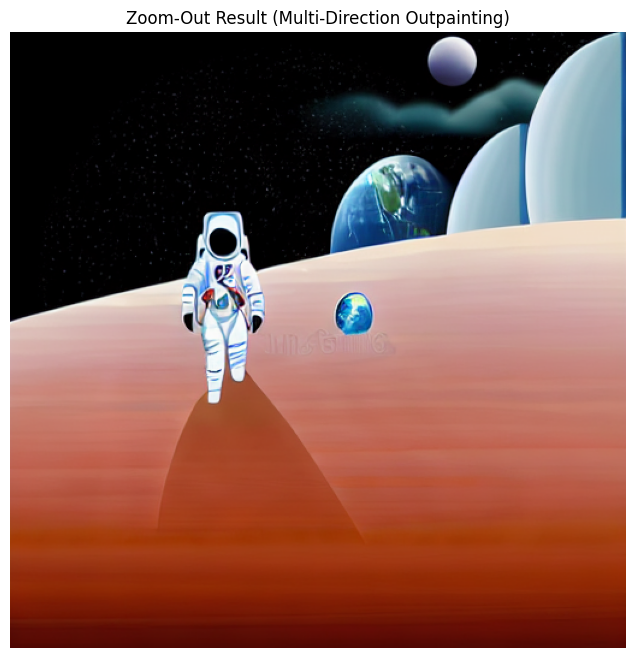

In [40]:
zoom_out_img = inpaint_engine(
    image=zoom_canvas,
    mask=zoom_mask,
    prompt=(
        "wide angle 2d digital art illustration of an astronaut and broken satellite on the moon surface, "
        "vast lunar craters, planet earth and stars in dark space sky, clean vector art style"
    ),
    seed=222,
    strength=0.95,
    guidance_scale=8.5,
    num_inference_steps=40
)

plt.figure(figsize=(8, 8))
plt.imshow(zoom_out_img)
plt.title("Zoom-Out Result (Multi-Direction Outpainting)")
plt.axis("off")
plt.show()

## **Base + Refiner Image Generation**

  0%|          | 0/40 [00:00<?, ?it/s]

You have disabled the safety checker for <class 'diffusers.pipelines.stable_diffusion.pipeline_stable_diffusion_img2img.StableDiffusionImg2ImgPipeline'> by passing `safety_checker=None`. Ensure that you abide to the conditions of the Stable Diffusion license and do not expose unfiltered results in services or applications open to the public. Both the diffusers team and Hugging Face strongly recommend to keep the safety filter enabled in all public facing circumstances, disabling it only for use-cases that involve analyzing network behavior or auditing its results. For more information, please have a look at https://github.com/huggingface/diffusers/pull/254 .


  0%|          | 0/10 [00:00<?, ?it/s]

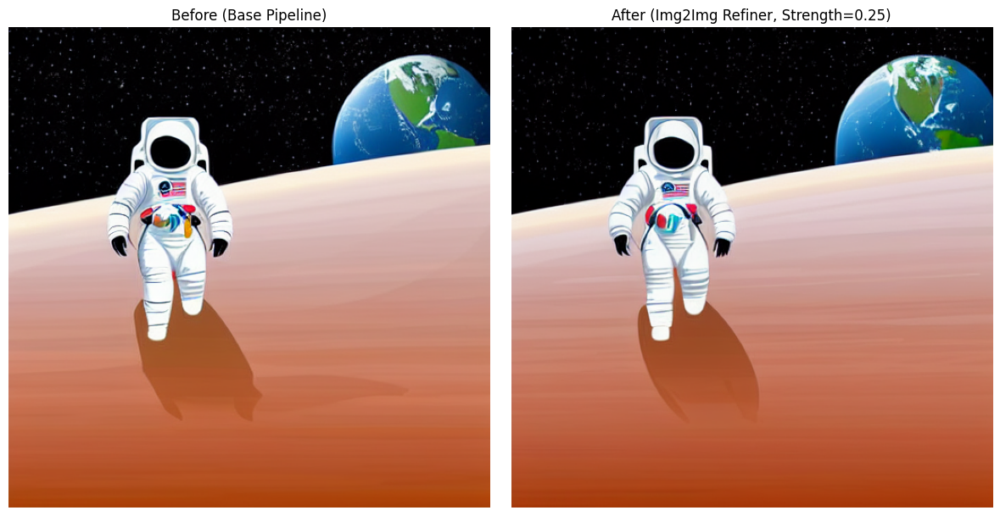

In [41]:
gc.collect()
if device == "cuda":
    torch.cuda.empty_cache()

pipe.scheduler = DPMSolverMultistepScheduler.from_config(default_scheduler_config)
gen_stage1 = torch.Generator(device=device).manual_seed(SEED)

base_stage_img = pipe(
    prompt=PROMPT_ASTRONAUT,
    negative_prompt=NEGATIVE_PROMPT,
    guidance_scale=8.5,
    num_inference_steps=40,
    generator=gen_stage1
).images[0]

pipe_refiner = StableDiffusionImg2ImgPipeline(**pipe.components).to(device)
gen_stage2 = torch.Generator(device=device).manual_seed(SEED)

refined_img = pipe_refiner(
    prompt=PROMPT_ASTRONAUT + ", ultra crisp vector details, refined shading, high clarity",
    negative_prompt=NEGATIVE_PROMPT,
    image=base_stage_img,
    strength=0.25,
    guidance_scale=8.0,
    num_inference_steps=40,
    generator=gen_stage2
).images[0]

fig, axes = plt.subplots(1, 2, figsize=(12, 6))
axes[0].imshow(base_stage_img)
axes[0].set_title("Before (Base Pipeline)")
axes[1].imshow(refined_img)
axes[1].set_title("After (Img2Img Refiner, Strength=0.25)")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

In [42]:
!pip freeze > requirements.txt

from google.colab import files
files.download("requirements.txt")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>